In [1]:
#setup/libraries
import obspy
import h5py
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.signal import butter, filtfilt
from IPython.display import HTML
from obspy.signal.trigger import classic_sta_lta

In [2]:
## Processing Paths & Settings

import sys
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_PATH = PROJECT_ROOT / "src"
DATA_PATH = PROJECT_ROOT / "data"
OUTPUT_PATH = PROJECT_ROOT / "processed_data"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from preprocess import preprocess_trace

TARGET_FS = 20.0
WINDOW_SAMPLES = 1200
PRE_P_SAMPLES = 200

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

In [3]:
## Dataset Discovery & Processing

import pandas as pd
import numpy as np


# 1. Indentify Dataset Collumns

COLUMN_ALIASES = {
    "waveform": ["waveform", "data", "trace", "signal"],
    "fs": ["sampling_rate", "smprt", "sample_rate", "fs"],
    "start": ["trace_start", "trace_start_time", "start_time"],
    "p": ["p_arrival", "phase_epoch", "p_time", "arrival_time"],
    "event": ["ev_id", "evid", "event_id", "event"]
}


def identify_columns(df):
    """Identify the columns required for preprocessing."""

    mapping = {}

    for required, aliases in COLUMN_ALIASES.items():

        match = next(
            (col for col in aliases if col in df.columns),
            None
        )

        if match is None:
            return None

        mapping[required] = match

    return mapping


# 2. Check Dataset Compatibility

def check_dataset_compatibility(df, columns):
    """
    Check whether a dataset contains records suitable
    for the common preprocessing pipeline.
    """

    if columns is None or df.empty:
        return False, "Missing required columns or empty dataset"

    valid_records = 0

    for _, row in df.iterrows():

        try:
            waveform = np.asarray(
                row[columns["waveform"]],
                dtype=float
            )

            fs = float(row[columns["fs"]])
            start = float(row[columns["start"]])
            arrival = float(row[columns["p"]])
            event = row[columns["event"]]

            if (
                waveform.ndim != 1
                or len(waveform) == 0
                or not np.isfinite(waveform).all()
                or not np.isfinite(fs)
                or fs < TARGET_FS
                or not np.isfinite(start)
                or not np.isfinite(arrival)
                or pd.isna(event)
            ):
                continue

            # Calculate P arrival sample
            p_index = (arrival - start) * fs

            # Check whether the complete window fits
            if (
                p_index < PRE_P_SAMPLES
                or p_index + (WINDOW_SAMPLES - PRE_P_SAMPLES)
                > len(waveform)
            ):
                continue

            valid_records += 1

        except (
            ValueError,
            TypeError,
            IndexError,
            OverflowError,
            FloatingPointError
        ):
            continue

    if valid_records == 0:
        return False, "No usable waveform records"

    return True, f"{valid_records}/{len(df)} records usable"


# 3. Preprocess Datasets

def process_dataset(df, dataset_name, columns):

    processed = []
    metadata = []
    skipped = 0

    for idx, row in df.iterrows():

        try:
            waveform = np.asarray(
                row[columns["waveform"]],
                dtype=float
            )

            fs = float(row[columns["fs"]])

            # Calculate P arrival in original samples
            p_index = (
                (float(row[columns["p"]]) -
                 float(row[columns["start"]])) * fs
            )

            # Apply shared preprocessing pipeline
            trace, info = preprocess_trace(
                waveform,
                fs,
                p_index=p_index,
                do_normalize=True
            )

            processed.append(trace)

            metadata.append({
                "dataset": dataset_name,
                "original_index": idx,
                "event_id": row[columns["event"]],
                "sampling_rate": fs,
                "p_index": info["p_index"],
                "window_p_index": PRE_P_SAMPLES
            })

        except (
            ValueError,
            TypeError,
            IndexError,
            OverflowError,
            FloatingPointError
        ):
            skipped += 1

    if not processed:
        return (
            np.empty((0, WINDOW_SAMPLES)),
            pd.DataFrame(metadata),
            skipped
        )

    return (
        np.stack(processed),
        pd.DataFrame(metadata),
        skipped
    )


# 4. Dataset Discovery

DATASETS = sorted(DATA_PATH.glob("*.h5"))

processed_datasets = {}
metadata_datasets = {}
dataset_status = {}

if not DATASETS:
    raise FileNotFoundError(
        f"No HDF5 datasets found in {DATA_PATH}"
    )


# 5. Dataset Check/Process

for path in DATASETS:

    print(f"\nChecking dataset: {path.name}")

    try:

        # Load dataset
        df = pd.read_hdf(path, key="df")

        # Identify required columns
        columns = identify_columns(df)

        # Check compatibility
        compatible, reason = check_dataset_compatibility(
            df,
            columns
        )

        if not compatible:

            dataset_status[path.name] = "Skipped: " + reason
            print(dataset_status[path.name])
            continue

        print("Compatibility passed:", reason)

        # Process compatible records
        processed, metadata, skipped = process_dataset(
            df,
            path.stem,
            columns
        )

        if len(processed) == 0:

            dataset_status[path.name] = (
                "Skipped: no waveforms successfully processed"
            )

            print(dataset_status[path.name])
            continue

        # Store results
        processed_datasets[path.stem] = processed
        metadata_datasets[path.stem] = metadata

        dataset_status[path.name] = "Processed"

        print("Successfully processed:", len(processed))
        print("Skipped records:", skipped)

    except (
        ValueError,
        KeyError,
        OSError,
        TypeError,
        ImportError
    ) as error:

        dataset_status[path.name] = f"Skipped: {error}"
        print(dataset_status[path.name])


# 6. Dataset Processing Summary

if not processed_datasets:
    raise ValueError(
        "No compatible datasets found. "
        "Check dataset formats and required columns."
    )

print("\n========== DATASET SUMMARY ==========")

for name, status in dataset_status.items():
    print(f"{name}: {status}")

print("\nCompatible datasets:", len(processed_datasets))

print(
    "Total processed waveforms:",
    sum(len(data) for data in processed_datasets.values())
)


Checking dataset: Digital_data_fdsn.h5
Skipped: No usable waveform records

Checking dataset: final_lasa_data.h5
Skipped: Missing required columns or empty dataset

Checking dataset: final_llnl_uncut_data.h5
Compatibility passed: 2699/2956 records usable
Successfully processed: 2679
Skipped records: 277

Checking dataset: Full_FSU_Data_uncut.h5
Compatibility passed: 7634/8837 records usable
Successfully processed: 7128
Skipped records: 1709

========== DATASET SUMMARY ==========
Digital_data_fdsn.h5: Skipped: No usable waveform records
final_lasa_data.h5: Skipped: Missing required columns or empty dataset
final_llnl_uncut_data.h5: Processed
Full_FSU_Data_uncut.h5: Processed

Compatible datasets: 2
Total processed waveforms: 9807


In [4]:
## Combine Datasets

waveforms = []
event_ids = []
dataset_labels = []
metadata_frames = []

for dataset_name, processed in processed_datasets.items():

    metadata = metadata_datasets[dataset_name].copy()

    waveforms.append(processed)
    metadata_frames.append(metadata)

    dataset_labels.extend(
        [dataset_name] * len(processed)
    )

    event_ids.extend([
        f"{dataset_name}_{event}"
        for event in metadata["event_id"]
    ])

X = np.concatenate(waveforms, axis=0)

event_ids = np.asarray(event_ids)
dataset_labels = np.asarray(dataset_labels)

metadata = pd.concat(
    metadata_frames,
    ignore_index=True
)

assert len(X) == len(event_ids)
assert len(X) == len(dataset_labels)
assert len(X) == len(metadata)

print("Combined waveform shape:", X.shape)
print("Total waveforms:", len(X))
print("Datasets included:", list(processed_datasets.keys()))

Combined waveform shape: (9807, 1200)
Total waveforms: 9807
Datasets included: ['final_llnl_uncut_data', 'Full_FSU_Data_uncut']


In [5]:
## Preprocessing Validation

assert X.ndim == 2
assert X.shape[1] == WINDOW_SAMPLES

assert np.isfinite(X).all()

peak_amplitudes = np.max(np.abs(X), axis=1)
assert np.allclose(peak_amplitudes, 1.0)

assert len(X) == len(event_ids)
assert len(X) == len(dataset_labels)
assert len(X) == len(metadata)

assert np.all(
    metadata["window_p_index"].to_numpy()
    == PRE_P_SAMPLES
)

assert np.all(
    metadata["p_index"].to_numpy() >= 0
)

# Check for zero-amplitude waveforms
assert np.all(peak_amplitudes > 0)

# Check that each dataset has matching metadata and waveform counts
for name in processed_datasets:
    assert len(processed_datasets[name]) == len(metadata_datasets[name])
	
# Confirm no empty datasets were included
assert all(len(data) > 0 for data in processed_datasets.values())

# Confirm dataset labels match metadata
assert np.array_equal(
    dataset_labels,
    metadata["dataset"].to_numpy()
)

print("PREPROCESSING VALIDATION PASSED")
print("Total waveforms:", len(X))
print("Samples per waveform:", X.shape[1])
print("Sampling rate:", TARGET_FS, "Hz")
print("Window duration:", WINDOW_SAMPLES / TARGET_FS, "seconds")
print("P arrival position:", PRE_P_SAMPLES)
print("All waveforms finite: Yes")
print("All waveforms peak-normalized: Yes")
print("Event identifiers preserved: Yes")

PREPROCESSING VALIDATION PASSED
Total waveforms: 9807
Samples per waveform: 1200
Sampling rate: 20.0 Hz
Window duration: 60.0 seconds
P arrival position: 200
All waveforms finite: Yes
All waveforms peak-normalized: Yes
Event identifiers preserved: Yes


In [6]:
## Save Processed Datasets

# Save individual datasets
for name, data in processed_datasets.items():

    np.savez_compressed(
        OUTPUT_PATH / f"{name}_processed.npz",
        waveforms=data
    )

    metadata_datasets[name].to_csv(
        OUTPUT_PATH / f"{name}_metadata.csv",
        index=False
    )

# Save combined dataset without EQ/UNE labels
np.savez_compressed(
    OUTPUT_PATH / "final_preprocessed_dataset.npz",
    X=X,
    event_ids=event_ids,
    dataset_labels=dataset_labels
)

metadata.to_csv(
    OUTPUT_PATH / "final_metadata.csv",
    index=False
)

print("Preprocessed datasets saved successfully.")

Preprocessed datasets saved successfully.


In [2]:
import os

print("1. Looking in the main folder (../):")
try:
    print(os.listdir("../"))
except Exception as e:
    print("Error:", e)

print("\n2. Looking inside the data folder (../data/):")
try:
    print(os.listdir("../data/"))
except Exception as e:
    print("Error:", e)

1. Looking in the main folder (../):
['.git', 'data', 'notebooks', 'README.md', 'requirements.txt']

2. Looking inside the data folder (../data/):
['cbt_processed_20160903_120154.932+0000.sgy', 'TERRA.h5']


In [3]:
# loading raw das data from a seafloor fiber-optic cable.
# this specific .sgy file captures seismic wave propagation from the pawnee m5.8 earthquake.
# we use these earthquake waves as a proxy to test the basic stages of our detection algorithms.

FILE_PATH = r"../data/cbt_processed_20160903_120154.932+0000.sgy"

st_pawnee = obspy.read(FILE_PATH, format='SEGY')
st_pawnee.detrend("linear")

# convert to 2d grid (channels x time)
data_p = np.array([tr.data for tr in st_pawnee], dtype=float)

# time derivative for going from disp/strain to velo/strain-rate (following lindsey 2017)
fs_p = 50.0
data_p_vel = np.diff(data_p, axis=1) * fs_p

# remove laser drift by subtracting median
data_p_vel = data_p_vel - np.median(data_p_vel, axis=0)

# using correct filter: 0.02-2 hz (lindsey 2017's exact parameters)
# (note: previously tried 1-20hz but it buried the signal entirely)
b_p, a_p = butter(4, [0.02, 2.0], btype='bandpass', fs=fs_p)
data_p_filtered = filtfilt(b_p, a_p, data_p_vel, axis=1)

# filtering out bad sensors/channels based on standard deviation
channel_std_p = np.std(data_p_filtered, axis=1)
median_std_p = np.median(channel_std_p)

good_p = np.where(
    (channel_std_p < 3 * median_std_p) &
    (channel_std_p > 0.1 * median_std_p)
)[0]

data_p_good = data_p_filtered[good_p, :]

print(f"preprocessing done!")
print(f"kept {len(good_p)} out of {data_p_filtered.shape[0]} functional channels")

preprocessing done!
kept 530 out of 626 functional channels


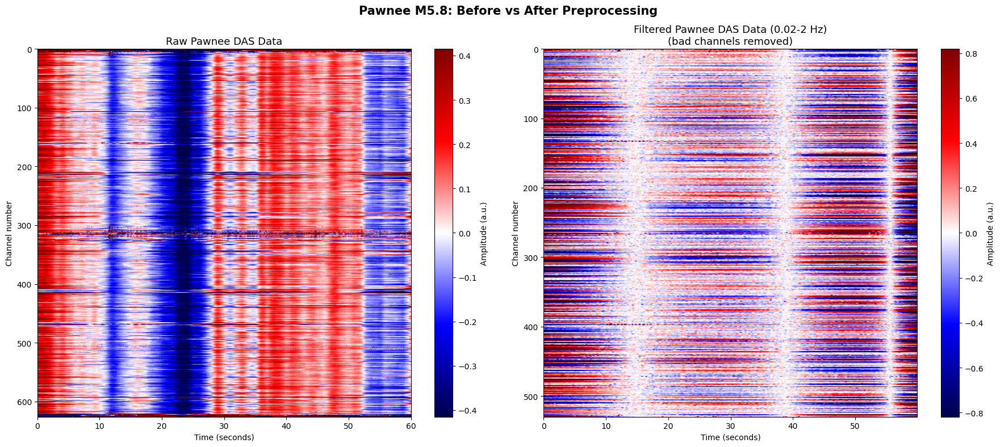

In [4]:
# raw vs fully "preprocessed" for visual comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# raw
im0 = axes[0].imshow(data_p, aspect='auto', cmap='seismic',
               extent=[0, 60, data_p.shape[0], 0],
               vmin=-np.percentile(np.abs(data_p), 95),
               vmax=np.percentile(np.abs(data_p), 95))
axes[0].set_title('Raw Pawnee DAS Data', fontsize=13)
axes[0].set_xlabel('Time (seconds)')
axes[0].set_ylabel('Channel number')
plt.colorbar(im0, ax=axes[0], label='Amplitude (a.u.)')

# filtered
im1 = axes[1].imshow(data_p_good, aspect='auto', cmap='seismic',
               extent=[0, 59.98, len(good_p), 0],
               vmin=-np.percentile(np.abs(data_p_good), 95),
               vmax=np.percentile(np.abs(data_p_good), 95))
axes[1].set_title('Filtered Pawnee DAS Data (0.02-2 Hz)\n(bad channels removed)', fontsize=13)
axes[1].set_xlabel('Time (seconds)')
axes[1].set_ylabel('Channel number')
plt.colorbar(im1, ax=axes[1], label='Amplitude (a.u.)')

plt.suptitle('Pawnee M5.8: Before vs After Preprocessing', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [5]:
# cook inlet hdf5 dataset to test real wave propagation across an 81km seafloor cable
# data can be downloaded directly if not found in the 'data' folder
import os

h5file = r"../data/TERRA.h5"

if not os.path.exists(h5file):
    print("downloading TERRA.h5 dataset...")
    subprocess.run(['curl', '-o', h5file, '--create-dirs',
                    'https://dasway.ess.washington.edu/gci/events/2023-07-28/11726446/TERRA.h5'])

# read data and metadata
data_ci = h5py.File(h5file, 'r')
attrs = dict(data_ci['Acquisition'].attrs)
das = np.array(data_ci['Acquisition/Raw[0]/RawData'])
data_ci.close()

# get metadata parameters
dt = 1 / attrs['MaximumFrequency'] / 2  # time step
dx = attrs['SpatialSamplingInterval']   # channel spacing in meters
nt, nx = das.shape
t = np.linspace(0, nt * dt, nt)         # time axis in seconds
x = np.linspace(0, nx * dx, nx)         # distance axis in meters
x_km = x / 1000                         # convert to km

print(f"sampling rate: {1/dt} Hz | total cable length: {x_km[-1]:.2f} km")

sampling rate: 25.0 Hz | total cable length: 81.65 km


In [6]:
# bandpass filter 2-10 hz to isolate seismic waves from ocean noise
b_ci, a_ci = butter(2, [2, 10], btype='bandpass', fs=1/dt)
das_filtered = filtfilt(b_ci, a_ci, das, axis=0)

# phase to strain conversion parameters
gl = attrs['GaugeLength']
wavelength = 1550e-9  #1550 nm laser wavelength
refractive_index = 1.4682
photoelastic_coefficient = 0.78

correction_factor = wavelength / (photoelastic_coefficient * 4 * np.pi * refractive_index * gl)
das_strain = das_filtered * correction_factor

print(f"correction factor applied: {correction_factor:.2e}")
print(f"max strain value: {np.max(np.abs(das_strain)):.2e}")

correction factor applied: 6.14e-09
max strain value: 1.11e-06


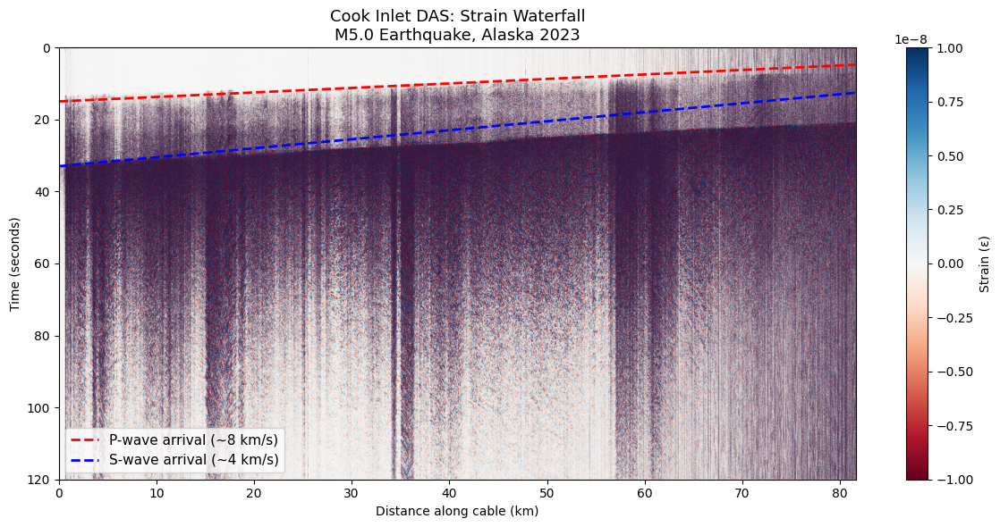

In [7]:
# strain waterfall to visualize the p-wave and s-wave arrivals
plt.figure(figsize=(12, 6))
plt.imshow(das_strain, aspect='auto', cmap='RdBu',
           vmin=-0.1e-7, vmax=0.1e-7,
           extent=[x_km[0], x_km[-1], t[-1], t[0]])

test_x = np.linspace(x_km[0], x_km[-1])

# tracking p-wave arrival (~8 km/s)
vel_p = 8
test_t_p = 15 - test_x / vel_p
plt.plot(test_x, test_t_p, 'r--', linewidth=2, label='P-wave arrival (~8 km/s)')

# tracking s-wave arrival (~4 km/s)
vel_s = 4
test_t_s = 33 - test_x / vel_s
plt.plot(test_x, test_t_s, 'b--', linewidth=2, label='S-wave arrival (~4 km/s)')

plt.colorbar(label='Strain (ε)')
plt.ylabel('Time (seconds)')
plt.xlabel('Distance along cable (km)')
plt.title('Cook Inlet DAS: Strain Waterfall\nM5.0 Earthquake, Alaska 2023', fontsize=13)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

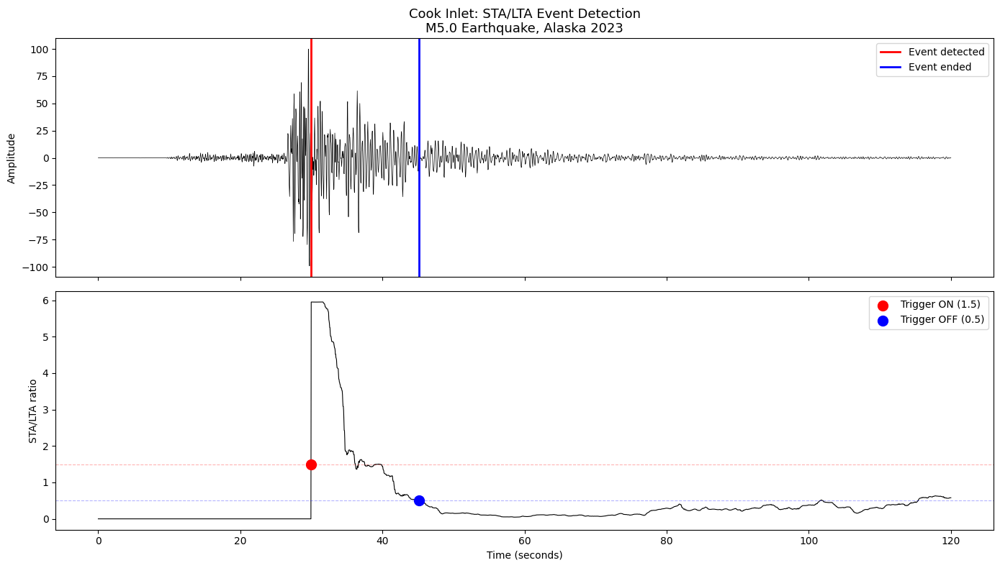

In [8]:
# sta/lta (short-time average over long-time average) on a single channel
# choosing a middle data channel (#4265) about ~40 km along the cable
channel = 4265
time_axis = t

# using classic_sta_lta from obspy
df = 1/dt
cft = classic_sta_lta(das_filtered[:, channel], int(5 * df), int(30 * df))

# trigger thresholds to map to our custom plot
trigger_on_idx = np.where(cft > 1.5)[0][0]
trigger_on_time = time_axis[trigger_on_idx]

trigger_off_idx = np.where((cft < 0.5) & (time_axis > trigger_on_time))[0][0]
trigger_off_time = time_axis[trigger_off_idx]

# custom subplots for event detection visual
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# top panel: seismic trace with trigger lines
axes[0].plot(time_axis, das_filtered[:, channel], 'k-', linewidth=0.5)
axes[0].axvline(x=trigger_on_time, color='r', linewidth=2, label='Event detected')
axes[0].axvline(x=trigger_off_time, color='b', linewidth=2, label='Event ended')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Cook Inlet: STA/LTA Event Detection\nM5.0 Earthquake, Alaska 2023', fontsize=13)
axes[0].legend()

# bottom panel: sta/lta ratio logic
axes[1].plot(time_axis, cft, 'k-', linewidth=0.8)
axes[1].scatter(trigger_on_time, 1.5, color='r', s=100, zorder=5, label='Trigger ON (1.5)')
axes[1].scatter(trigger_off_time, 0.5, color='b', s=100, zorder=5, label='Trigger OFF (0.5)')
axes[1].axhline(y=1.5, color='r', linestyle='--', linewidth=0.8, alpha=0.3)
axes[1].axhline(y=0.5, color='b', linestyle='--', linewidth=0.8, alpha=0.3)
axes[1].set_ylabel('STA/LTA ratio')
axes[1].set_xlabel('Time (seconds)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
# short animation to visualize wavefront propagation (might be off)
frames_idx = range(200, 400, 10)  

fig, ax = plt.subplots(figsize=(10, 4))

# base plot layer
ax.imshow(das_filtered, aspect='auto', cmap='plasma',
          vmin=-1, vmax=1,
          extent=[x_km[0], x_km[-1], t[-1], t[0]])

# moving time bar
line, = ax.plot([x_km[0], x_km[-1]], [t[200], t[200]], 'y-', linewidth=2)
time_text = ax.text(1, t[200]-2, f't = {t[200]:.1f}s', color='yellow', fontsize=11, fontweight='bold')

ax.set_xlabel('Distance along cable (km)')
ax.set_ylabel('Time (seconds)')
ax.set_title('Cook Inlet — Wave Arrival Animation')

# animation function
def animate(i):
    line.set_ydata([t[i], t[i]])
    time_text.set_y(t[i] - 2)
    time_text.set_text(f't = {t[i]:.1f}s')
    return line, time_text

ani = animation.FuncAnimation(fig, animate, frames=frames_idx, interval=100, blit=True)
plt.close() # prevents duplicate static plot from generating above video

# display interactive html video player inside jupyter
HTML(ani.to_jshtml())